## Part 1 — Kafka quick start (guided, not graded)

## Part 1, Step 1: A topic is a set of logs

### Predictions

Command: `kafka-topics.sh --describe --topic clicks`

| Question | Prediction | Reasoning |
|---|---|---|
| How many partitions will be listed? | **2** | The topic was created with `--partitions 2`, so there will be a Partition 0 and a Partition 1. |
| What is the replication factor? | **1** | We passed `--replication-factor 1`, and there is only a single broker. |
| Which broker leads each partition? | **Broker 1** (the only one) | With one broker, it must lead both partitions. `Replicas` and `Isr` will show the same ID. |
| What are the offsets right now? | **0** in both partitions | The topic is new and empty, so no events exist yet. |
| How long does Kafka keep events? | **7 days** (`retention.ms` = 604800000) | This is the default, and it applies whether or not anyone reads the events. |

Expected output:

```
Topic: clicks   PartitionCount: 2   ReplicationFactor: 1   Configs: ...
    Topic: clicks   Partition: 0   Leader: 1   Replicas: 1   Isr: 1
    Topic: clicks   Partition: 1   Leader: 1   Replicas: 1   Isr: 1
```

#### Output:
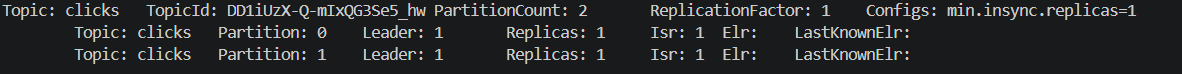

The output matched all predictions:

- `PartitionCount: 2`, with one line each for Partition 0 and Partition 1.
- `ReplicationFactor: 1`.
- `Leader: 1`, `Replicas: 1` and `Isr: 1` on both partitions, since there is only one broker.
- `Configs: min.insync.replicas=1`, which fits a single-broker setup.

The output also showed `TopicId` and the empty fields `Elr` and `LastKnownElr`, which are newer Kafka features.

## Part 1, Step 2: Keys decide the partition

### Predictions

| Question | Prediction | Reasoning |
|---|---|---|
| Does `user-1` land in the same partition on both runs? | **Yes** | The partition is `hash(key) mod number of partitions`, which is the same on every run. |
| Where do events without a key go? | **Spread over both partitions** | Without a key there is nothing to hash, so Kafka distributes events across partitions. |
| What happens to the offsets on the second run? | **They continue** from the first run | Partitions are append-only logs, so new events get the next offsets. |

### Observation

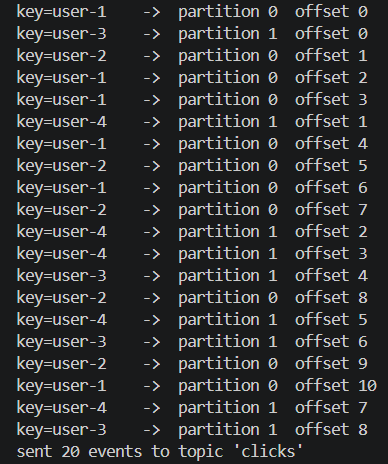  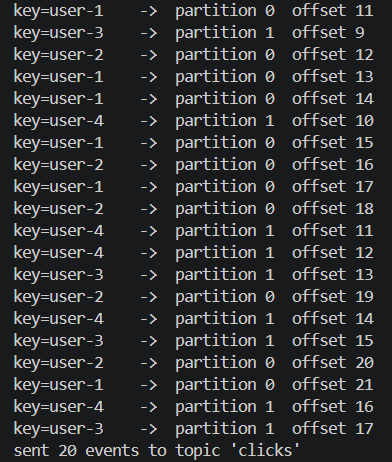  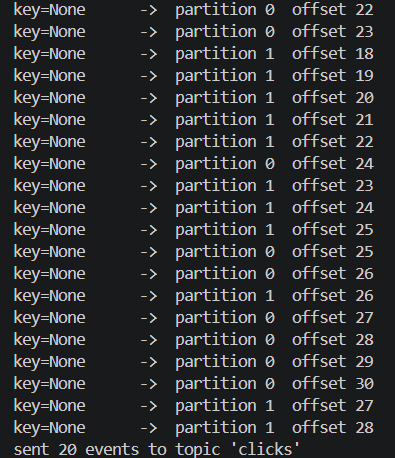


The output matched all predictions:

- **Same key, same partition:** `user-1` and `user-2` went to partition 0 and `user-3` and `user-4` went to partition 1, in both keyed runs. The partition is `hash(key) mod number of partitions`, so it does not change between runs.
- **Offsets continue:** run 1 ended at offset 10 in partition 0 and offset 8 in partition 1. Run 2 started at offsets 11 and 9, because partitions are append-only logs.
- **No key, no ordering:** in the `--no-key` run, events were spread over both partitions (`key=None` appears in partition 0 and partition 1). The order per user is therefore lost.
- **Total:** 3 runs × 20 events = 60 events, spread over partition 0 (offsets 0 to 30) and partition 1 (offsets 0 to 28).


## Part 1, Step 3: Consumer groups share the work

### Predictions

| Question | Prediction | Reasoning |
|---|---|---|
| A alone in group `dashboard` | A gets partitions 0 and 1 | It is the only consumer. |
| After B joins | A and B get one partition each | Rebalance: the group splits the partitions. |
| After C joins | C is idle, A and B keep one partition each | Within a group, one partition goes to one consumer, and there are more consumers than partitions. |
| Who reads which keys? | The owner of partition 0 reads `user-1` and `user-2`. The owner of partition 1 reads `user-3` and `user-4`. | Key → partition is fixed (Step 2), and each partition has one reader. |
| Which events does X (group `billing`) read? | All events from both partitions | Groups are independent, so a second group reads everything on its own. |
| Does X change `dashboard`? | No | Separate groups do not trigger rebalances in each other. |


### Observation

#### 1. Consumer A starts (group `dashboard`, alone)

Command: `py consumer.py --group dashboard --name A`

```
[A] joined group 'dashboard' on topic 'clicks' (Ctrl+C to stop)
[A] assigned partitions: [0, 1]
[A] partition 1 offset    0  key=user-3   seq=2
[A] partition 1 offset    1  key=user-4   seq=6
[A] partition 1 offset    2  key=user-4   seq=11
[A] partition 1 offset    3  key=user-4   seq=12
[A] partition 1 offset    4  key=user-3   seq=13
[A] partition 1 offset    5  key=user-4   seq=15
[A] partition 1 offset    6  key=user-3   seq=16
[A] partition 1 offset    7  key=user-4   seq=19
[A] partition 1 offset    8  key=user-3   seq=20
[A] partition 1 offset    9  key=user-3   seq=2
[A] partition 1 offset   10  key=user-4   seq=6
[A] partition 1 offset   11  key=user-4   seq=11
[A] partition 1 offset   12  key=user-4   seq=12
[A] partition 1 offset   13  key=user-3   seq=13
[A] partition 1 offset   14  key=user-4   seq=15
[A] partition 1 offset   15  key=user-3   seq=16
[A] partition 1 offset   16  key=user-4   seq=19
[A] partition 1 offset   17  key=user-3   seq=20
[A] partition 1 offset   18  key=None     seq=3
[A] partition 1 offset   19  key=None     seq=4
[A] partition 1 offset   20  key=None     seq=5
[A] partition 1 offset   21  key=None     seq=6
[A] partition 1 offset   22  key=None     seq=7
[A] partition 1 offset   23  key=None     seq=9
[A] partition 1 offset   24  key=None     seq=10
[A] partition 1 offset   25  key=None     seq=11
[A] partition 1 offset   26  key=None     seq=14
[A] partition 1 offset   27  key=None     seq=19
[A] partition 1 offset   28  key=None     seq=20
[A] partition 0 offset    0  key=user-1   seq=1
[A] partition 0 offset    1  key=user-2   seq=3
[A] partition 0 offset    2  key=user-1   seq=4
[A] partition 0 offset    3  key=user-1   seq=5
[A] partition 0 offset    4  key=user-1   seq=7
[A] partition 0 offset    5  key=user-2   seq=8
[A] partition 0 offset    6  key=user-1   seq=9
[A] partition 0 offset    7  key=user-2   seq=10
[A] partition 0 offset    8  key=user-2   seq=14
[A] partition 0 offset    9  key=user-2   seq=17
[A] partition 0 offset   10  key=user-1   seq=18
[A] partition 0 offset   11  key=user-1   seq=1
[A] partition 0 offset   12  key=user-2   seq=3
[A] partition 0 offset   13  key=user-1   seq=4
[A] partition 0 offset   14  key=user-1   seq=5
[A] partition 0 offset   15  key=user-1   seq=7
[A] partition 0 offset   16  key=user-2   seq=8
[A] partition 0 offset   17  key=user-1   seq=9
[A] partition 0 offset   18  key=user-2   seq=10
[A] partition 0 offset   19  key=user-2   seq=14
[A] partition 0 offset   20  key=user-2   seq=17
[A] partition 0 offset   21  key=user-1   seq=18
[A] partition 0 offset   22  key=None     seq=1
[A] partition 0 offset   23  key=None     seq=2
[A] partition 0 offset   24  key=None     seq=8
[A] partition 0 offset   25  key=None     seq=12
[A] partition 0 offset   26  key=None     seq=13
[A] partition 0 offset   27  key=None     seq=15
[A] partition 0 offset   28  key=None     seq=16
[A] partition 0 offset   29  key=None     seq=17
[A] partition 0 offset   30  key=None     seq=18
```

- A is alone in the group, so it gets **both partitions** (`[0, 1]`).
- A read each partition **from its own offset 0**, because offsets are counted per partition:
  - partition 1: offsets 0 to 28 (29 events)
  - partition 0: offsets 0 to 30 (31 events)
  - Total: 60 events (3 producer runs × 20).
- A new group has no saved position, so it starts at the earliest offset of every partition it gets.

#### 2. Consumer B joins (group `dashboard`)

Command: `py consumer.py --group dashboard --name B`

Output of **B**:

```
[B] joined group 'dashboard' on topic 'clicks' (Ctrl+C to stop)
[B] assigned partitions: [1]
```

Output of **A** after B joined (end of its log):

```
[A] partition 0 offset   30  key=None     seq=18
[A] revoked partitions:  [0, 1]
[A] assigned partitions: [0]
```

- B was assigned partition `[1]`, and A had to give up everything (`revoked [0, 1]`) and then got only `[0]`. This is a **rebalance**: the partitions are split so each consumer has one.
- B printed no old events. The group had already read them, and Kafka stores the committed offset per group and partition.

#### 3. Consumer C joins (group `dashboard`)

Command: `py consumer.py --group dashboard --name C`

Output of **C**:

```
[C] joined group 'dashboard' on topic 'clicks' (Ctrl+C to stop)
[C] assigned partitions: none (idle)
```

Output of **B** (new lines):

```
[B] revoked partitions:  [1]
[B] assigned partitions: [1]
```

Output of **A** (new lines):

```
[A] revoked partitions:  [0]
[A] assigned partitions: [0]
```

- **C is idle.** Within a group, one partition goes to one consumer, and with 2 partitions and 3 consumers, one consumer has no work.
- C's arrival still triggered a **rebalance**: A and B each gave up their partition and got the same one back.

#### 4. Producer sends 20 events (group `dashboard` running)

Command: `py producer.py`

Output of the **producer**:

```
key=user-1    ->  partition 0  offset 31
key=user-3    ->  partition 1  offset 29
key=user-2    ->  partition 0  offset 32
key=user-1    ->  partition 0  offset 33
key=user-1    ->  partition 0  offset 34
key=user-4    ->  partition 1  offset 30
key=user-1    ->  partition 0  offset 35
key=user-2    ->  partition 0  offset 36
key=user-1    ->  partition 0  offset 37
key=user-2    ->  partition 0  offset 38
key=user-4    ->  partition 1  offset 31
key=user-4    ->  partition 1  offset 32
key=user-3    ->  partition 1  offset 33
key=user-2    ->  partition 0  offset 39
key=user-4    ->  partition 1  offset 34
key=user-3    ->  partition 1  offset 35
key=user-2    ->  partition 0  offset 40
key=user-1    ->  partition 0  offset 41
key=user-4    ->  partition 1  offset 36
key=user-3    ->  partition 1  offset 37
sent 20 events to topic 'clicks'
```

Output of **A**:

```
[A] partition 0 offset   31  key=user-1   seq=1
[A] partition 0 offset   32  key=user-2   seq=3
[A] partition 0 offset   33  key=user-1   seq=4
[A] partition 0 offset   34  key=user-1   seq=5
[A] partition 0 offset   35  key=user-1   seq=7
[A] partition 0 offset   36  key=user-2   seq=8
[A] partition 0 offset   37  key=user-1   seq=9
[A] partition 0 offset   38  key=user-2   seq=10
[A] partition 0 offset   39  key=user-2   seq=14
[A] partition 0 offset   40  key=user-2   seq=17
[A] partition 0 offset   41  key=user-1   seq=18
```

Output of **B**:

```
[B] partition 1 offset   29  key=user-3   seq=2
[B] partition 1 offset   30  key=user-4   seq=6
[B] partition 1 offset   31  key=user-4   seq=11
[B] partition 1 offset   32  key=user-4   seq=12
[B] partition 1 offset   33  key=user-3   seq=13
[B] partition 1 offset   34  key=user-4   seq=15
[B] partition 1 offset   35  key=user-3   seq=16
[B] partition 1 offset   36  key=user-4   seq=19
[B] partition 1 offset   37  key=user-3   seq=20
```

Output of **C**: no new output (still idle).

- **A (partition 0)** read only `user-1` and `user-2` (offsets 31 to 41).
- **B (partition 1)** read only `user-3` and `user-4` (offsets 29 to 37).
- **C** printed nothing.
- Together A and B received all 20 events with no overlap. Within each user, the `seq` numbers stay in order, because all events of one key sit in one partition with one reader.

#### 5. Second group: consumer X (group `billing`)

Command: `py consumer.py --group billing --name X`

```
[X] joined group 'billing' on topic 'clicks' (Ctrl+C to stop)
[X] assigned partitions: [0, 1]
[X] partition 1 offset    0  key=user-3   seq=2
[X] partition 1 offset    1  key=user-4   seq=6
[X] partition 1 offset    2  key=user-4   seq=11
[X] partition 1 offset    3  key=user-4   seq=12
[X] partition 1 offset    4  key=user-3   seq=13
[X] partition 1 offset    5  key=user-4   seq=15
[X] partition 1 offset    6  key=user-3   seq=16
[X] partition 1 offset    7  key=user-4   seq=19
[X] partition 1 offset    8  key=user-3   seq=20
[X] partition 1 offset    9  key=user-3   seq=2
[X] partition 1 offset   10  key=user-4   seq=6
[X] partition 1 offset   11  key=user-4   seq=11
[X] partition 1 offset   12  key=user-4   seq=12
[X] partition 1 offset   13  key=user-3   seq=13
[X] partition 1 offset   14  key=user-4   seq=15
[X] partition 1 offset   15  key=user-3   seq=16
[X] partition 1 offset   16  key=user-4   seq=19
[X] partition 1 offset   17  key=user-3   seq=20
[X] partition 1 offset   18  key=None     seq=3
[X] partition 1 offset   19  key=None     seq=4
[X] partition 1 offset   20  key=None     seq=5
[X] partition 1 offset   21  key=None     seq=6
[X] partition 1 offset   22  key=None     seq=7
[X] partition 1 offset   23  key=None     seq=9
[X] partition 1 offset   24  key=None     seq=10
[X] partition 1 offset   25  key=None     seq=11
[X] partition 1 offset   26  key=None     seq=14
[X] partition 1 offset   27  key=None     seq=19
[X] partition 1 offset   28  key=None     seq=20
[X] partition 1 offset   29  key=user-3   seq=2
[X] partition 1 offset   30  key=user-4   seq=6
[X] partition 1 offset   31  key=user-4   seq=11
[X] partition 1 offset   32  key=user-4   seq=12
[X] partition 1 offset   33  key=user-3   seq=13
[X] partition 1 offset   34  key=user-4   seq=15
[X] partition 1 offset   35  key=user-3   seq=16
[X] partition 1 offset   36  key=user-4   seq=19
[X] partition 1 offset   37  key=user-3   seq=20
[X] partition 0 offset    0  key=user-1   seq=1
[X] partition 0 offset    1  key=user-2   seq=3
[X] partition 0 offset    2  key=user-1   seq=4
[X] partition 0 offset    3  key=user-1   seq=5
[X] partition 0 offset    4  key=user-1   seq=7
[X] partition 0 offset    5  key=user-2   seq=8
[X] partition 0 offset    6  key=user-1   seq=9
[X] partition 0 offset    7  key=user-2   seq=10
[X] partition 0 offset    8  key=user-2   seq=14
[X] partition 0 offset    9  key=user-2   seq=17
[X] partition 0 offset   10  key=user-1   seq=18
[X] partition 0 offset   11  key=user-1   seq=1
[X] partition 0 offset   12  key=user-2   seq=3
[X] partition 0 offset   13  key=user-1   seq=4
[X] partition 0 offset   14  key=user-1   seq=5
[X] partition 0 offset   15  key=user-1   seq=7
[X] partition 0 offset   16  key=user-2   seq=8
[X] partition 0 offset   17  key=user-1   seq=9
[X] partition 0 offset   18  key=user-2   seq=10
[X] partition 0 offset   19  key=user-2   seq=14
[X] partition 0 offset   20  key=user-2   seq=17
[X] partition 0 offset   21  key=user-1   seq=18
[X] partition 0 offset   22  key=None     seq=1
[X] partition 0 offset   23  key=None     seq=2
[X] partition 0 offset   24  key=None     seq=8
[X] partition 0 offset   25  key=None     seq=12
[X] partition 0 offset   26  key=None     seq=13
[X] partition 0 offset   27  key=None     seq=15
[X] partition 0 offset   28  key=None     seq=16
[X] partition 0 offset   29  key=None     seq=17
[X] partition 0 offset   30  key=None     seq=18
[X] partition 0 offset   31  key=user-1   seq=1
[X] partition 0 offset   32  key=user-2   seq=3
[X] partition 0 offset   33  key=user-1   seq=4
[X] partition 0 offset   34  key=user-1   seq=5
[X] partition 0 offset   35  key=user-1   seq=7
[X] partition 0 offset   36  key=user-2   seq=8
[X] partition 0 offset   37  key=user-1   seq=9
[X] partition 0 offset   38  key=user-2   seq=10
[X] partition 0 offset   39  key=user-2   seq=14
[X] partition 0 offset   40  key=user-2   seq=17
[X] partition 0 offset   41  key=user-1   seq=18
```

- **X got both partitions** (`[0, 1]`), since it is the only consumer in its group.
- **X read all events from the beginning:** partition 0 offsets 0 to 41 and partition 1 offsets 0 to 37, which is 80 events (4 producer runs × 20). A different group reads everything on its own.
- **No rebalance in `dashboard`:** A, B and C printed no new `revoked` or `assigned` lines when X joined.

### Summary

- **Within a group, one partition goes to one consumer.** A and B got one partition each, and C was idle because there were more consumers than partitions.
- **Every join or leave triggers a rebalance,** and a partition can move to another consumer.
- **Another group (`billing`) reads all events independently,** without changing `dashboard`.

#### 6. Stopping the consumers (Ctrl+C)

Output of **A**:

```
[A] revoked partitions:  [0, 1]
[A] assigned partitions: [0]
[A] revoked partitions:  [0]
[A] assigned partitions: [0]
[A] partition 0 offset   31  key=user-1   seq=1
... (offsets 32 to 40) ...
[A] partition 0 offset   41  key=user-1   seq=18
[A] revoked partitions:  [0]
[A] stopped after 71 events
```

Output of **B**:

```
[B] assigned partitions: [1]
[B] partition 1 offset   29  key=user-3   seq=2
... (offsets 30 to 36) ...
[B] partition 1 offset   37  key=user-3   seq=20
[B] revoked partitions:  [1]
[B] assigned partitions: [0]
[B] revoked partitions:  [0]
[B] stopped after 9 events
```

Output of **C**:

```
[C] assigned partitions: none (idle)
[C] revoked partitions:  []
[C] assigned partitions: [1]
[C] partition 1 offset   34  key=user-4   seq=15
[C] partition 1 offset   35  key=user-3   seq=16
[C] partition 1 offset   36  key=user-4   seq=19
[C] partition 1 offset   37  key=user-3   seq=20
[C] revoked partitions:  [1]
[C] assigned partitions: [0, 1]
[C] partition 1 offset   34  key=user-4   seq=15
[C] partition 1 offset   35  key=user-3   seq=16
[C] partition 1 offset   36  key=user-4   seq=19
[C] partition 1 offset   37  key=user-3   seq=20
[C] revoked partitions:  [0, 1]
[C] stopped after 8 events
```

Output of **X** (group `billing`):

```
[X] partition 0 offset   41  key=user-1   seq=18
[X] revoked partitions:  [0, 1]
[X] stopped after 80 events
```

- **A stopped after 71 events:** 60 old events + 11 new ones.
- **Stopping consumers also triggers rebalances.** When A left, partition 1 moved to C, which had been idle. When B left, C took over both partitions.
- **C read offsets 34 to 37 of partition 1 twice**, although B had already read them. Offsets are committed periodically, so after a rebalance a consumer can restart from an older committed position. This is **at-least-once delivery**: some events can be processed more than once.
- **X (group `billing`) saw no rebalances** from the `dashboard` consumers joining or leaving.

## Part 1, Step 4: Offsets, where a group continues

### Predictions

| Question | Prediction | Reasoning |
|---|---|---|
| Where does `dashboard` stand when all consumers are stopped? | CURRENT-OFFSET 42 (partition 0) and 38 (partition 1) | The group last read offsets 41 and 37, so the next ones to read are 42 and 38. |
| What are LOG-END-OFFSET and LAG after 20 more events? | LOG-END-OFFSET grows by the number of new events per partition (about 53 and 47). LAG equals that number (about 11 and 9, 20 in total). | Nobody is reading, so the group position stays and the log grows. |
| What happens when A comes back? | A gets both partitions and reads only the 20 new events | The group continues at its committed offset. |
| What is the lag after A has caught up? | 0 | CURRENT-OFFSET equals LOG-END-OFFSET. |
| What happens after resetting `billing` to the earliest offset and restarting X? | X replays all events from offset 0 | The reset moves the committed offset back. Nothing is deleted. |

### Observation

All consumers (A, B, C and X) were stopped with `Ctrl+C` first (see Step 3, section 6).

#### 1. Producer sends 20 more events

Command: `python producer.py`

```
key=user-1    ->  partition 0  offset 42
key=user-3    ->  partition 1  offset 38
key=user-2    ->  partition 0  offset 43
key=user-1    ->  partition 0  offset 44
key=user-1    ->  partition 0  offset 45
key=user-4    ->  partition 1  offset 39
key=user-1    ->  partition 0  offset 46
key=user-2    ->  partition 0  offset 47
key=user-1    ->  partition 0  offset 48
key=user-2    ->  partition 0  offset 49
key=user-4    ->  partition 1  offset 40
key=user-4    ->  partition 1  offset 41
key=user-3    ->  partition 1  offset 42
key=user-2    ->  partition 0  offset 50
key=user-4    ->  partition 1  offset 43
key=user-3    ->  partition 1  offset 44
key=user-2    ->  partition 0  offset 51
key=user-1    ->  partition 0  offset 52
key=user-4    ->  partition 1  offset 45
key=user-3    ->  partition 1  offset 46
sent 20 events to topic 'clicks'
```

#### 2. Describe group `dashboard` (before A comes back)

Command: `docker exec -it kafka kafka-consumer-groups.sh --bootstrap-server localhost:9092 --describe --group dashboard`

```
Consumer group 'dashboard' has no active members.

GROUP           TOPIC           PARTITION  CURRENT-OFFSET  LOG-END-OFFSET  LAG             CONSUMER-ID     HOST            CLIENT-ID
dashboard       clicks          1          38              47              9               -               -               -
dashboard       clicks          0          42              53              11              -               -               -
```

- The group has **no active members**, since all consumers are stopped.
- `CURRENT-OFFSET` is 42 (partition 0) and 38 (partition 1): the position where the group stopped, as predicted. Kafka kept it while nobody was reading.
- `LOG-END-OFFSET` is 53 and 47: the log grew by the 20 new events (11 in partition 0, 9 in partition 1).
- `LAG` is 11 + 9 = **20**, exactly the events the group has not read yet.

#### 3. Consumer A comes back (group `dashboard`)

Command: `python consumer.py --group dashboard --name A`

```
[A] joined group 'dashboard' on topic 'clicks' (Ctrl+C to stop)
[A] assigned partitions: [0, 1]
[A] partition 0 offset   42  key=user-1   seq=1
[A] partition 0 offset   43  key=user-2   seq=3
[A] partition 0 offset   44  key=user-1   seq=4
[A] partition 0 offset   45  key=user-1   seq=5
[A] partition 0 offset   46  key=user-1   seq=7
[A] partition 0 offset   47  key=user-2   seq=8
[A] partition 0 offset   48  key=user-1   seq=9
[A] partition 0 offset   49  key=user-2   seq=10
[A] partition 0 offset   50  key=user-2   seq=14
[A] partition 0 offset   51  key=user-2   seq=17
[A] partition 0 offset   52  key=user-1   seq=18
[A] partition 1 offset   38  key=user-3   seq=2
[A] partition 1 offset   39  key=user-4   seq=6
[A] partition 1 offset   40  key=user-4   seq=11
[A] partition 1 offset   41  key=user-4   seq=12
[A] partition 1 offset   42  key=user-3   seq=13
[A] partition 1 offset   43  key=user-4   seq=15
[A] partition 1 offset   44  key=user-3   seq=16
[A] partition 1 offset   45  key=user-4   seq=19
[A] partition 1 offset   46  key=user-3   seq=20
[A] revoked partitions:  [0, 1]
[A] stopped after 20 events
```

- A is alone in the group, so it got both partitions (`[0, 1]`).
- A read **only the 20 new events** (partition 0 offsets 42 to 52, partition 1 offsets 38 to 46). The old events were not replayed, because the group continues at its committed offset.
- This differs from the first run of A in Step 3, which replayed 60 events: that group was new and had no saved position.

#### 4. Describe group `dashboard` (after A has caught up and stopped)

Command: `docker exec -it kafka kafka-consumer-groups.sh --bootstrap-server localhost:9092 --describe --group dashboard`

```
Consumer group 'dashboard' has no active members.

GROUP           TOPIC           PARTITION  CURRENT-OFFSET  LOG-END-OFFSET  LAG             CONSUMER-ID     HOST            CLIENT-ID
dashboard       clicks          1          47              47              0               -               -               -
dashboard       clicks          0          53              53              0               -               -               -
```

- `CURRENT-OFFSET` now equals `LOG-END-OFFSET` (47 and 53), so the **lag is 0** in both partitions.
- A committed its final positions when it stopped, so the group's saved position moved from 38/42 to 47/53.

#### 5. Describe group `billing` (before the reset)

Command: `docker exec -it kafka kafka-consumer-groups.sh --bootstrap-server localhost:9092 --describe --group billing`

```
Consumer group 'billing' has no active members.

GROUP           TOPIC           PARTITION  CURRENT-OFFSET  LOG-END-OFFSET  LAG             CONSUMER-ID     HOST            CLIENT-ID
billing         clicks          1          38              47              9               -               -               -
billing         clicks          0          42              53              11              -               -               -
```

- `billing` is still at offsets 42 and 38, where X stopped, so its lag is 11 + 9 = 20.
- Each group has its own position: `dashboard` has lag 0, while `billing` still has lag 20.

#### 6. Consumer X restarts without a reset (group `billing`)

Command: `python consumer.py --group billing --name X`

```
[X] joined group 'billing' on topic 'clicks' (Ctrl+C to stop)
[X] assigned partitions: [0, 1]
[X] partition 0 offset   42  key=user-1   seq=1
[X] partition 0 offset   43  key=user-2   seq=3
[X] partition 0 offset   44  key=user-1   seq=4
[X] partition 0 offset   45  key=user-1   seq=5
[X] partition 0 offset   46  key=user-1   seq=7
[X] partition 0 offset   47  key=user-2   seq=8
[X] partition 0 offset   48  key=user-1   seq=9
[X] partition 0 offset   49  key=user-2   seq=10
[X] partition 0 offset   50  key=user-2   seq=14
[X] partition 0 offset   51  key=user-2   seq=17
[X] partition 0 offset   52  key=user-1   seq=18
[X] partition 1 offset   38  key=user-3   seq=2
[X] partition 1 offset   39  key=user-4   seq=6
[X] partition 1 offset   40  key=user-4   seq=11
[X] partition 1 offset   41  key=user-4   seq=12
[X] partition 1 offset   42  key=user-3   seq=13
[X] partition 1 offset   43  key=user-4   seq=15
[X] partition 1 offset   44  key=user-3   seq=16
[X] partition 1 offset   45  key=user-4   seq=19
[X] partition 1 offset   46  key=user-3   seq=20
[X] revoked partitions:  [0, 1]
[X] stopped after 20 events
```

- X read only the 20 events it had missed, so it **continued from its committed offset**, like A did.

#### 7. Reset `billing` to the earliest offset

X was stopped first (`[X] stopped after 20 events`), because Kafka only resets groups without active members.

Command: `docker exec -it kafka kafka-consumer-groups.sh --bootstrap-server localhost:9092 --group billing --topic clicks --reset-offsets --to-earliest --execute`

```
GROUP                          TOPIC                          PARTITION  NEW-OFFSET     
billing                        clicks                         1          0              
billing                        clicks                         0          0              
```

- The committed offsets of `billing` were moved back to **0** in both partitions. No events were deleted, only the group's position changed.

#### 8. Describe group `billing` (after the reset)

Command: `docker exec -it kafka kafka-consumer-groups.sh --bootstrap-server localhost:9092 --describe --group billing`

```
Consumer group 'billing' has no active members.

GROUP           TOPIC           PARTITION  CURRENT-OFFSET  LOG-END-OFFSET  LAG             CONSUMER-ID     HOST            CLIENT-ID
billing         clicks          1          0               47              47              -               -               -
billing         clicks          0          0               53              53              -               -               -
```

- `CURRENT-OFFSET` is 0 in both partitions, while `LOG-END-OFFSET` is still 47 and 53. The **lag is now the whole log** (47 + 53 = 100 events), because the group's position was moved back and nothing was deleted.

#### 9. Consumer X replays the whole topic (group `billing`)

Command: `python consumer.py --group billing --name X`

```
[X] joined group 'billing' on topic 'clicks' (Ctrl+C to stop)
[X] assigned partitions: [0, 1]
[X] partition 0 offset    0  key=user-1   seq=1
[X] partition 0 offset    1  key=user-2   seq=3
[X] partition 0 offset    2  key=user-1   seq=4
[X] partition 0 offset    3  key=user-1   seq=5
[X] partition 0 offset    4  key=user-1   seq=7
[X] partition 0 offset    5  key=user-2   seq=8
[X] partition 0 offset    6  key=user-1   seq=9
[X] partition 0 offset    7  key=user-2   seq=10
[X] partition 0 offset    8  key=user-2   seq=14
[X] partition 0 offset    9  key=user-2   seq=17
[X] partition 0 offset   10  key=user-1   seq=18
[X] partition 0 offset   11  key=user-1   seq=1
[X] partition 0 offset   12  key=user-2   seq=3
[X] partition 0 offset   13  key=user-1   seq=4
[X] partition 0 offset   14  key=user-1   seq=5
[X] partition 0 offset   15  key=user-1   seq=7
[X] partition 0 offset   16  key=user-2   seq=8
[X] partition 0 offset   17  key=user-1   seq=9
[X] partition 0 offset   18  key=user-2   seq=10
[X] partition 0 offset   19  key=user-2   seq=14
[X] partition 0 offset   20  key=user-2   seq=17
[X] partition 0 offset   21  key=user-1   seq=18
[X] partition 0 offset   22  key=None     seq=1
[X] partition 0 offset   23  key=None     seq=2
[X] partition 0 offset   24  key=None     seq=8
[X] partition 0 offset   25  key=None     seq=12
[X] partition 0 offset   26  key=None     seq=13
[X] partition 0 offset   27  key=None     seq=15
[X] partition 0 offset   28  key=None     seq=16
[X] partition 0 offset   29  key=None     seq=17
[X] partition 0 offset   30  key=None     seq=18
[X] partition 0 offset   31  key=user-1   seq=1
[X] partition 0 offset   32  key=user-2   seq=3
[X] partition 0 offset   33  key=user-1   seq=4
[X] partition 0 offset   34  key=user-1   seq=5
[X] partition 0 offset   35  key=user-1   seq=7
[X] partition 0 offset   36  key=user-2   seq=8
[X] partition 0 offset   37  key=user-1   seq=9
[X] partition 0 offset   38  key=user-2   seq=10
[X] partition 0 offset   39  key=user-2   seq=14
[X] partition 0 offset   40  key=user-2   seq=17
[X] partition 0 offset   41  key=user-1   seq=18
[X] partition 0 offset   42  key=user-1   seq=1
[X] partition 0 offset   43  key=user-2   seq=3
[X] partition 0 offset   44  key=user-1   seq=4
[X] partition 0 offset   45  key=user-1   seq=5
[X] partition 0 offset   46  key=user-1   seq=7
[X] partition 0 offset   47  key=user-2   seq=8
[X] partition 0 offset   48  key=user-1   seq=9
[X] partition 0 offset   49  key=user-2   seq=10
[X] partition 0 offset   50  key=user-2   seq=14
[X] partition 0 offset   51  key=user-2   seq=17
[X] partition 0 offset   52  key=user-1   seq=18
[X] partition 1 offset    0  key=user-3   seq=2
[X] partition 1 offset    1  key=user-4   seq=6
[X] partition 1 offset    2  key=user-4   seq=11
[X] partition 1 offset    3  key=user-4   seq=12
[X] partition 1 offset    4  key=user-3   seq=13
[X] partition 1 offset    5  key=user-4   seq=15
[X] partition 1 offset    6  key=user-3   seq=16
[X] partition 1 offset    7  key=user-4   seq=19
[X] partition 1 offset    8  key=user-3   seq=20
[X] partition 1 offset    9  key=user-3   seq=2
[X] partition 1 offset   10  key=user-4   seq=6
[X] partition 1 offset   11  key=user-4   seq=11
[X] partition 1 offset   12  key=user-4   seq=12
[X] partition 1 offset   13  key=user-3   seq=13
[X] partition 1 offset   14  key=user-4   seq=15
[X] partition 1 offset   15  key=user-3   seq=16
[X] partition 1 offset   16  key=user-4   seq=19
[X] partition 1 offset   17  key=user-3   seq=20
[X] partition 1 offset   18  key=None     seq=3
[X] partition 1 offset   19  key=None     seq=4
[X] partition 1 offset   20  key=None     seq=5
[X] partition 1 offset   21  key=None     seq=6
[X] partition 1 offset   22  key=None     seq=7
[X] partition 1 offset   23  key=None     seq=9
[X] partition 1 offset   24  key=None     seq=10
[X] partition 1 offset   25  key=None     seq=11
[X] partition 1 offset   26  key=None     seq=14
[X] partition 1 offset   27  key=None     seq=19
[X] partition 1 offset   28  key=None     seq=20
[X] partition 1 offset   29  key=user-3   seq=2
[X] partition 1 offset   30  key=user-4   seq=6
[X] partition 1 offset   31  key=user-4   seq=11
[X] partition 1 offset   32  key=user-4   seq=12
[X] partition 1 offset   33  key=user-3   seq=13
[X] partition 1 offset   34  key=user-4   seq=15
[X] partition 1 offset   35  key=user-3   seq=16
[X] partition 1 offset   36  key=user-4   seq=19
[X] partition 1 offset   37  key=user-3   seq=20
[X] partition 1 offset   38  key=user-3   seq=2
[X] partition 1 offset   39  key=user-4   seq=6
[X] partition 1 offset   40  key=user-4   seq=11
[X] partition 1 offset   41  key=user-4   seq=12
[X] partition 1 offset   42  key=user-3   seq=13
[X] partition 1 offset   43  key=user-4   seq=15
[X] partition 1 offset   44  key=user-3   seq=16
[X] partition 1 offset   45  key=user-4   seq=19
[X] partition 1 offset   46  key=user-3   seq=20
[X] revoked partitions:  [0, 1]
[X] stopped after 100 events
```

- X read **all 100 events** again: partition 0 offsets 0 to 52 (53 events) and partition 1 offsets 0 to 46 (47 events), including events it had already processed before.
- Compare with section 6: without a reset, X read only the 20 events it had missed. The reset is what made it replay the history.
- `dashboard` was not affected, because the reset only changed the position of `billing`.

### Summary

- **The committed offset is the group's position in the log, stored in Kafka.** A returning consumer (A, X) continues where its group stopped and does not replay old events.
- **Lag shows how far behind a group is:** `dashboard` had lag 0 after A caught up, while `billing` kept lag 20 until X read the missing events.
- **Reading deletes nothing.** A reset (or a new group) replays the history, for example to fill a new service or to reprocess after a bug fix, without affecting other groups.